# NumCompute-Stream
This notebook replays a seeded synthetic classification stream in the original CSV order. The target rule changes halfway through, two categories arrive later, and numeric readings can be missing. See [the dataset notes](data/README.md) for generation rules.

Each chunk is evaluated using the last published tree and preprocessing snapshot before the pipeline learns from it. Warmup chunks help train the first tree and contribute zero evaluated rows.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == "demo":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np

from demo.stream_workflow import CHUNK_SIZE, DATA_PATH, common_evaluation, run_stream, stream_chunks
from numcompute_stream import StreamingStats
from numcompute_stream.visualise import (
    compare_models, plot_metric_over_time, plot_predictions_vs_ground_truth,
)

FIGURES = ROOT / "demo" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print(f"{DATA_PATH.name}: nominal chunk size {CHUNK_SIZE}")

stream_sample.csv: nominal chunk size 32


## Replay with a 64-row buffer
`stream_chunks` delegates CSV parsing to `numcompute_stream.io.iter_supervised_csv`. The shared `run_stream` helper configures a `TabularPreprocessor`, a `DecisionTreeClassifier`, and a `Pipeline`. It sends each pair of arrays to `StreamTrainer.fit_chunk(X, y)`, which scores first and then calls `pipeline.partial_fit(X, y)`. The observer receives the saved pre-update predictions and can accumulate independent descriptive statistics.

In [2]:
stats = StreamingStats(bin_edges=[-3, -2, -1, 0, 1, 2, 3])
ground_truth, predictions = [], []

def observe(X, y, result):
    stats.update_stats(X[:, :2])
    if result["status"] == "scored":
        ground_truth.append(y)
        predictions.append(result["y_pred"])

trainer = run_stream(stream_chunks(), buffer_size=64, on_chunk=observe)
print(f"{sum(row['chunk_samples'] for row in trainer.logs)} ordered rows in {len(trainer.logs)} chunks")
print(f"Final chunk size: {trainer.logs[-1]['chunk_samples']}")
print("Chunk  Status  Eval model  Builds  Pending  Train rows  Tree fit ms  Retrain ms  Update ms  Array KiB")
for index, row in enumerate(trainer.logs[:8], 1):
    t = row["timing"]
    print(f"{index:5}  {row['status']:6}  {str(row['evaluated_version']):>10}  "
          f"{row['retrain_count']:6}  {row['pending_samples']:7}  {row['trained_samples']:10}  "
          f"{t['tree_fit_s'] * 1000:11.3f}  {t['retrain_s'] * 1000:10.3f}  "
          f"{t['update_s'] * 1000:9.3f}  {row['memory']['total_bytes'] / 1024:9.2f}")

last = trainer.logs[-1]
print(f"Final builds: {last['retrain_count']}; rows still pending: {last['pending_samples']}")
for domain in ("cumulative", "rolling"):
    metric = last[domain]
    print(f"{domain}: accuracy {metric['accuracy']:.3f}, AUC {metric['auc']:.3f}, "
          f"evaluated rows {metric['n_samples']}")
print("Cumulative confusion matrix (true rows, predicted columns; labels 0, 1):")
print(trainer.metrics.result()["confusion_matrix"])

2000 ordered rows in 63 chunks
Final chunk size: 16
Chunk  Status  Eval model  Builds  Pending  Train rows  Tree fit ms  Retrain ms  Update ms  Array KiB
    1  warmup        None       0       32           0        0.000       0.000      0.769       1.19
    2  warmup        None       1        0          64       25.229      25.437     25.557       0.36
    3  scored           1       1       32           0        0.000       0.000      0.114       2.11
    4  scored           1       2        0          64        0.897       0.945      1.053       1.86
    5  scored           2       2       32           0        0.000       0.000      0.100       3.61
    6  scored           2       3        0          64        0.956       0.998      1.095       3.38
    7  scored           3       3       32           0        0.000       0.000      0.102       5.13
    8  scored           3       4        0          64        0.990       1.031      1.129       4.88
Final builds: 31; rows still p

## Cumulative statistics and accuracy
The descriptive statistics use the original numeric observations and omit NaN. The accuracy curve accumulates only pre-update evaluations, so it starts with gaps. The window in the replay log is the most recent 128 evaluated samples. Timing includes only the scopes named by each column. Array KiB estimates retained NumPy storage at the end of a chunk.

Columns: signal, context
Observed counts: [1861 1896]
Running means: [-0.033  0.   ]
Running variances: [1.001 1.024]
Exact quartiles: [[-0.715, -0.702], [-0.033, 0.028], [0.653, 0.705]]
Fixed-bin counts: [[44, 262, 641, 645, 227, 35], [38, 273, 611, 655, 279, 35]]


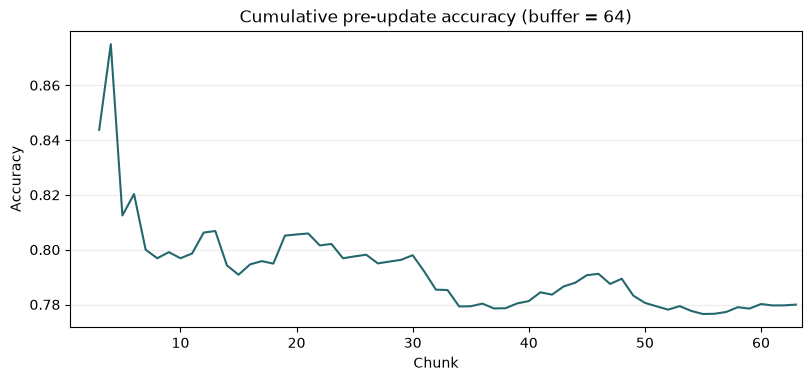

In [3]:
summary = stats.result([0.25, 0.5, 0.75])
print("Columns: signal, context")
print("Observed counts:", summary["count"])
print("Running means:", np.round(summary["mean"], 3))
print("Running variances:", np.round(summary["var"], 3))
print("Exact quartiles:", np.round(summary["quantile"], 3).tolist())
print("Fixed-bin counts:", summary["histogram"].tolist())

plot_metric_over_time(
    [row["cumulative"]["accuracy"] for row in trainer.logs],
    "Cumulative pre-update accuracy (buffer = 64)", "Accuracy",
    save_path=FIGURES / "stream_metric.png", show=True,
);

## Compare two buffer sizes
The same ordered chunks are replayed with a 256-row buffer. Both curves show per-chunk accuracy on chunks where **both** models could predict. The benchmark expands this experiment to three buffer sizes and reports sample-weighted accuracy and timing.

Shared evaluation starts at chunk 9.
Both models cover 1744 common rows.


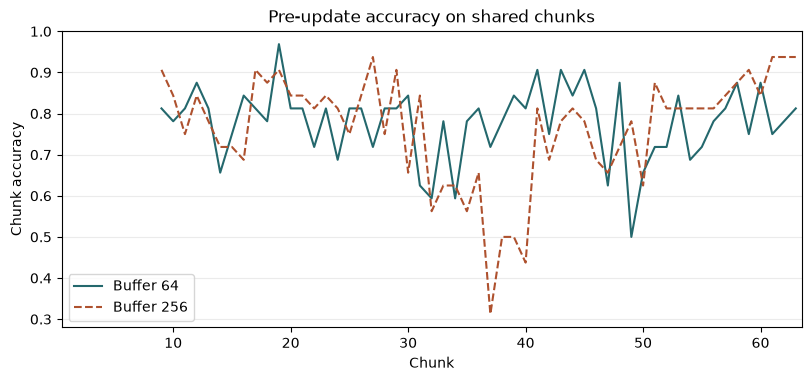

In [4]:
other = run_stream(stream_chunks(), buffer_size=256)
common = common_evaluation({64: trainer.logs, 256: other.logs})
print(f"Shared evaluation starts at chunk {np.flatnonzero(common)[0] + 1}.")
print(f"Both models cover {sum(row['chunk_samples'] for row, ready in zip(trainer.logs, common) if ready)} common rows.")
first = np.where(common, [row["batch"]["accuracy"] for row in trainer.logs], np.nan)
second = np.where(common, [row["batch"]["accuracy"] for row in other.logs], np.nan)
fig, ax = compare_models(first, second, ["Buffer 64", "Buffer 256"])
ax.set(title="Pre-update accuracy on shared chunks", ylabel="Chunk accuracy")
fig.savefig(FIGURES / "stream_compare.png", dpi=140)
plt.show()

## Pre-update predictions and ground truth
The first 96 evaluated samples keep their original order after warmup. An overlapping cross and circle represent a correct prediction. Scores come from a synthetic dataset with a controlled change in label rule.

Collected 1936 predictions from before the corresponding learning calls.


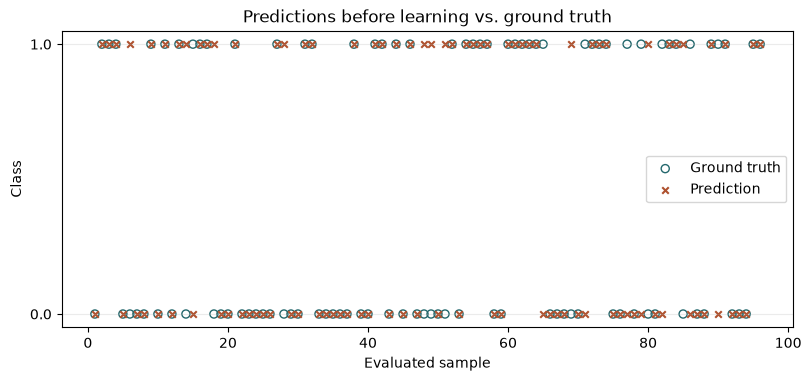

In [5]:
truth = np.concatenate(ground_truth)
predicted = np.concatenate(predictions)
print(f"Collected {len(predicted)} predictions from before the corresponding learning calls.")
plot_predictions_vs_ground_truth(
    truth[:96], predicted[:96],
    save_path=FIGURES / "stream_predictions.png", show=True,
);